# Used Cars Dataset — Exploratory Data Analysis

Covers: Shape & Structure, Missing Values, Duplicates, Univariate Analysis, Bivariate Analysis, Correlation Analysis, and Visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df = pd.read_csv('used_cars.csv')
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## 1. Shape, Columns & Data Types

In [2]:
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
df.columns.tolist()

Rows: 4009, Columns: 12


['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

In [3]:
df.dtypes

brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


## 2. Cleaning Numeric-Looking Columns

`price` (e.g. `"$10,300"`) and `milage` (e.g. `"51,000 mi."`) are stored as text and are converted to numeric here so the rest of the analysis can use them directly.

In [5]:
df['price_clean'] = (
    df['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
)
df['milage_clean'] = (
    df['milage'].str.replace(r'[a-zA-Z.,\s]', '', regex=True).astype(float)
)
df[['price', 'price_clean', 'milage', 'milage_clean']].head()

,price,price_clean,milage,milage_clean
0,"$10,300",10300.0,"51,000 mi.",51000.0
1,"$38,005",38005.0,"34,742 mi.",34742.0
2,"$54,598",54598.0,"22,372 mi.",22372.0
3,"$15,500",15500.0,"88,900 mi.",88900.0
4,"$34,999",34999.0,"9,835 mi.",9835.0


## 3. Missing Values

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0].sort_values('missing_count', ascending=False)
missing_df

,missing_count,missing_pct
clean_title,596,14.87
fuel_type,170,4.24
accident,113,2.82


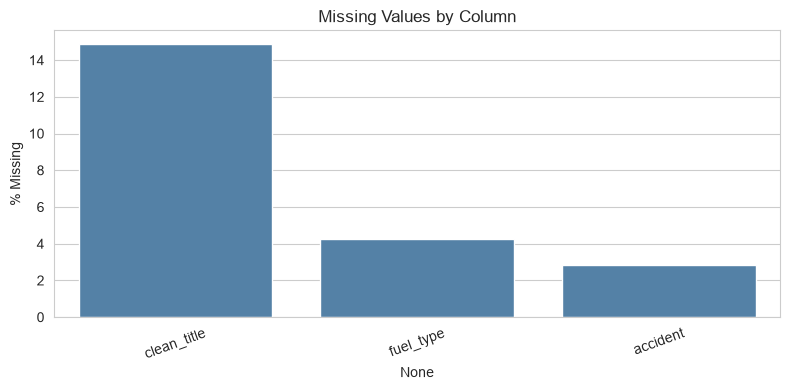

In [7]:
plt.figure(figsize=(8,4))
sns.barplot(x=missing_df.index, y=missing_df['missing_pct'], color='steelblue')
plt.ylabel('% Missing')
plt.title('Missing Values by Column')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

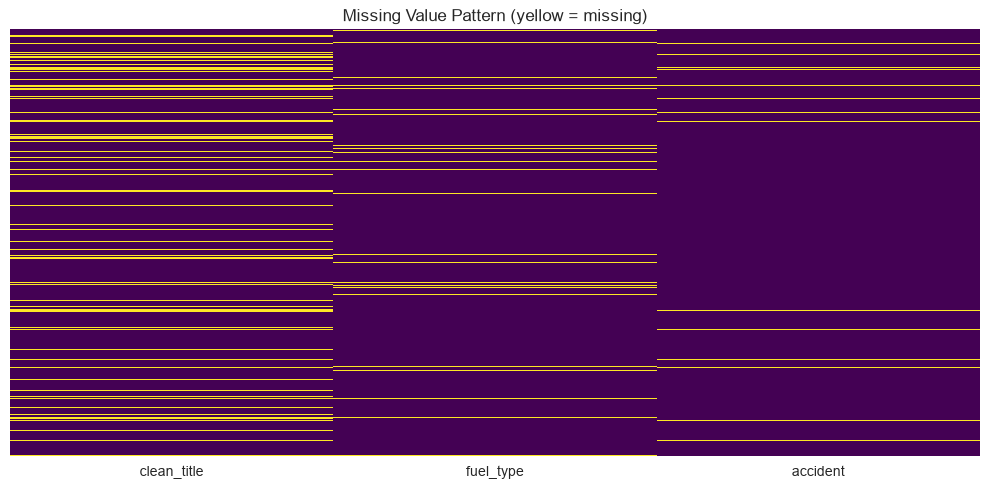

In [8]:
# Missing value heatmap - shows WHERE missing values fall across rows
plt.figure(figsize=(10,5))
sns.heatmap(df[missing_df.index].isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Value Pattern (yellow = missing)')
plt.tight_layout()
plt.show()

In [9]:
# How many rows are missing 2+ fields at once (co-occurring missingness)?
rows_missing_multi = (df.isnull().sum(axis=1) >= 2).sum()
print(f'Rows missing 2 or more fields: {rows_missing_multi} ({rows_missing_multi/len(df)*100:.1f}%)')

# clean_title is almost binary: only "Yes" ever appears, so NaN likely means "No" / unverified
print("\nclean_title unique non-null values:", df['clean_title'].dropna().unique())

Rows missing 2 or more fields: 135 (3.4%)

clean_title unique non-null values: ['Yes']


**Notes on missingness**

- `clean_title`: only value present is `"Yes"` — the 596 `NaN`s are effectively a second category (not clean / unknown), so this is likely **not missing at random**; consider encoding as a binary flag rather than imputing.
- `fuel_type` also has junk placeholder values (`"–"`, `"not supported"`) that behave like missing and should be folded into `NaN` before modeling.
- `accident` missingness (113 rows) looks closer to random/unreported.

## 4. Duplicates

In [10]:
full_dupes = df.duplicated().sum()
print(f'Fully duplicate rows: {full_dupes}')

Fully duplicate rows: 0


In [11]:
# Near-duplicates: same brand/model/year/mileage but possibly differing on other columns
subset_cols = ['brand', 'model', 'model_year', 'milage']
near_dupes = df.duplicated(subset=subset_cols).sum()
print(f'Rows duplicated on {subset_cols}: {near_dupes}')
df[df.duplicated(subset=subset_cols, keep=False)].sort_values(subset_cols)

Rows duplicated on ['brand', 'model', 'model_year', 'milage']: 3


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,price_clean,milage_clean
827,Ford,F-250 Lariat,2019,"85,000 mi.",Diesel,450.0HP 6.7L 8 Cylinder Engine Diesel Fuel,6-Speed A/T,White,Black,At least 1 accident or damage reported,Yes,"$55,000",55000.0,85000.0
1940,Ford,F-250 Lariat,2019,"85,000 mi.",Diesel,450.0HP 6.7L 8 Cylinder Engine Diesel Fuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$52,500",52500.0,85000.0
122,Rivian,R1S Adventure Package,2023,"2,500 mi.",NaN,835.0HP Electric Motor Electric Fuel System,A/T,Green,White,None reported,Yes,"$94,000",94000.0,2500.0
472,Rivian,R1S Adventure Package,2023,"2,500 mi.",NaN,835.0HP Electric Motor Electric Fuel System,A/T,Gray,Gray,None reported,Yes,"$91,000",91000.0,2500.0
526,Rivian,R1S Adventure Package,2023,250 mi.,NaN,835.0HP Electric Motor Electric Fuel System,A/T,Red,Black,NaN,NaN,"$94,000",94000.0,250.0
2184,Rivian,R1S Adventure Package,2023,250 mi.,NaN,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,Green,Black,NaN,NaN,"$97,500",97500.0,250.0


No exact duplicate rows exist. A handful of rows share brand/model/year/mileage — worth a manual look, but not necessarily errors (could be genuinely identical listings).

## 5. Univariate Analysis

### 5.1 Numeric Variables — Summary Statistics

In [12]:
df[['price_clean', 'milage_clean', 'model_year']].describe()

,price_clean,milage_clean,model_year
count,4.009000e+03,4009.000000,4009.000000
mean,4.455319e+04,64717.551010,2015.515590
std,7.871064e+04,52296.599459,6.104816
min,2.000000e+03,100.000000,1974.000000
25%,1.720000e+04,23044.000000,2012.000000
50%,3.100000e+04,52775.000000,2017.000000
75%,4.999000e+04,94100.000000,2020.000000
max,2.954083e+06,405000.000000,2024.000000


### 5.2 Numeric Variables — Distributions

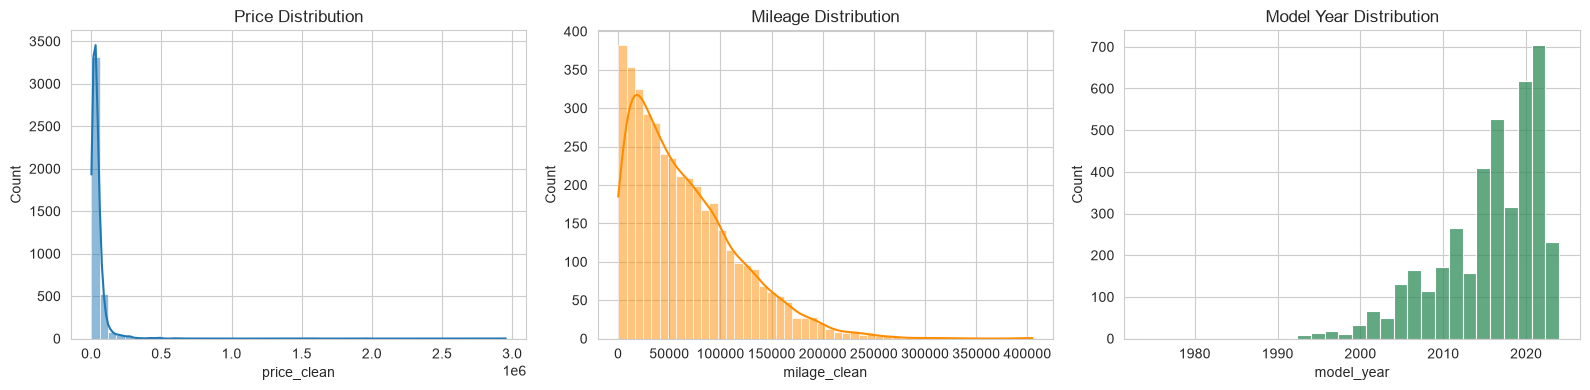

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))

sns.histplot(df['price_clean'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')

sns.histplot(df['milage_clean'], bins=50, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Mileage Distribution')

sns.histplot(df['model_year'], bins=30, ax=axes[2], color='seagreen')
axes[2].set_title('Model Year Distribution')

plt.tight_layout()
plt.show()

In [14]:
# Skewness / kurtosis
for col in ['price_clean', 'milage_clean', 'model_year']:
    print(f"{col}: skew={df[col].skew():.2f}, kurtosis={df[col].kurt():.2f}")

price_clean: skew=19.51, kurtosis=595.89
milage_clean: skew=1.16, kurtosis=1.75
model_year: skew=-1.09, kurtosis=1.10


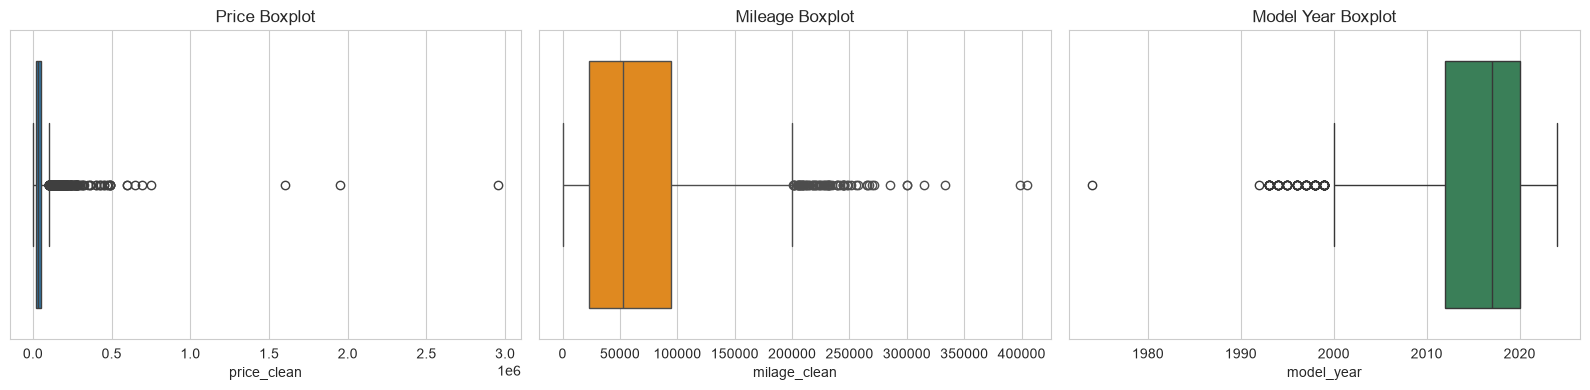

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.boxplot(x=df['price_clean'], ax=axes[0])
axes[0].set_title('Price Boxplot')
sns.boxplot(x=df['milage_clean'], ax=axes[1], color='darkorange')
axes[1].set_title('Mileage Boxplot')
sns.boxplot(x=df['model_year'], ax=axes[2], color='seagreen')
axes[2].set_title('Model Year Boxplot')
plt.tight_layout()
plt.show()

### 5.3 Categorical Variables — Frequency Counts

In [16]:
for col in ['fuel_type', 'accident', 'clean_title', 'transmission']:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- fuel_type ---
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

--- accident ---
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

--- clean_title ---
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

--- transmission ---
transmission
A/T                                  1037
8-Speed A/T                           406
Transmission w/Dual Shift Mode        398
6-Speed A/T                           362
6-Speed M/T                           248
                                     ... 
10-Speed Automatic with Overdrive       1
9-Speed Automatic with Auto-Shift       1
SCHEDULED FOR OR IN PRODUCTION          1
6 Speed Mt                              1
8-Speed Manual                

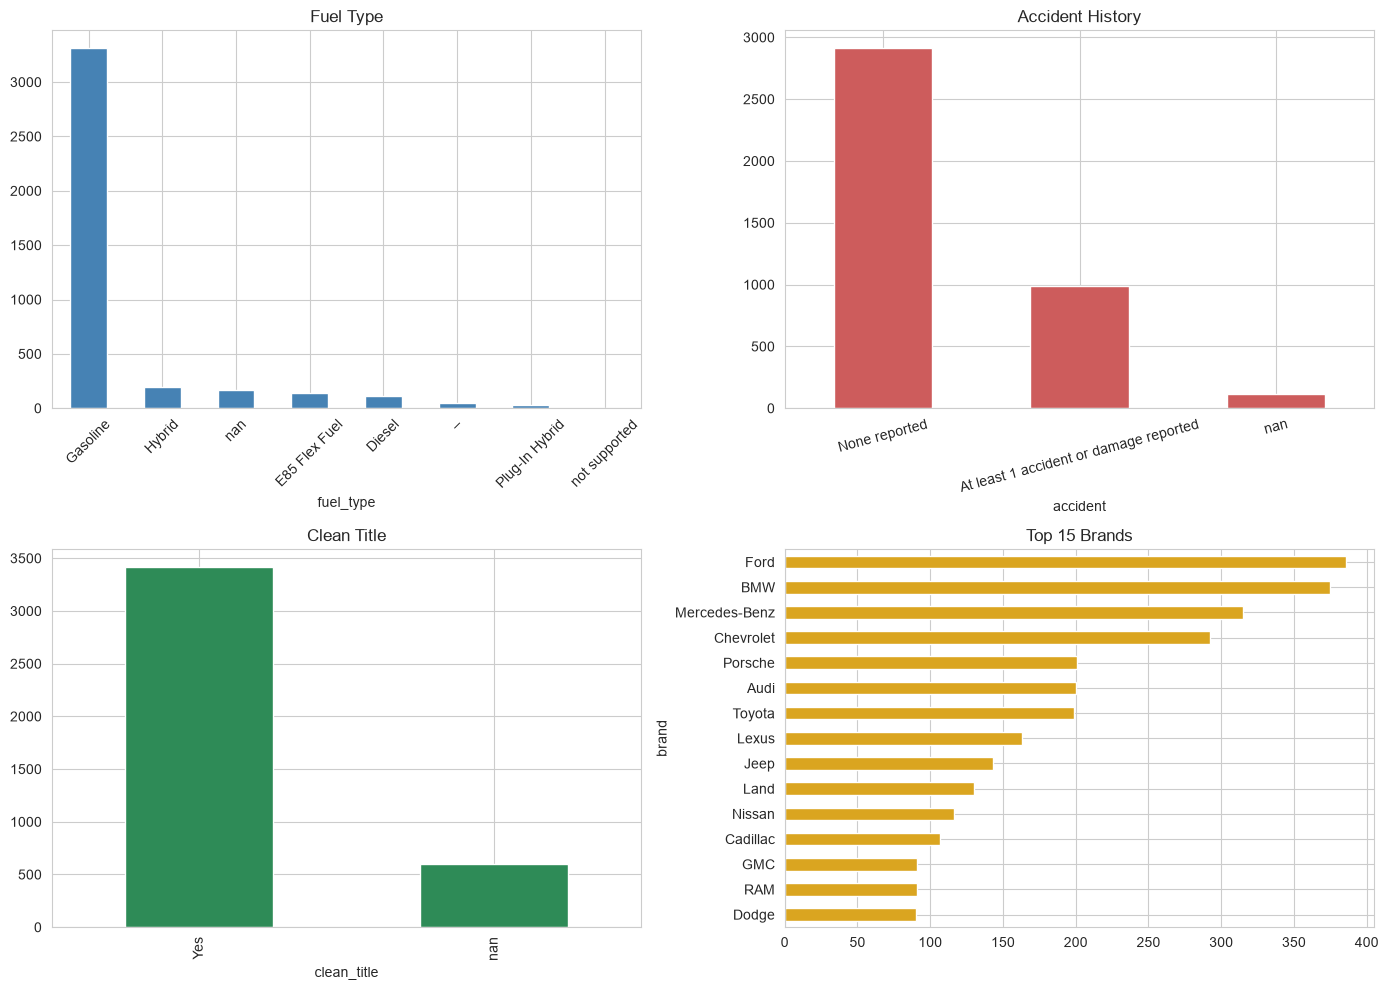

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

df['fuel_type'].value_counts(dropna=False).plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Fuel Type')
axes[0,0].tick_params(axis='x', rotation=45)

df['accident'].value_counts(dropna=False).plot(kind='bar', ax=axes[0,1], color='indianred')
axes[0,1].set_title('Accident History')
axes[0,1].tick_params(axis='x', rotation=15)

df['clean_title'].value_counts(dropna=False).plot(kind='bar', ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Clean Title')

df['brand'].value_counts().head(15).plot(kind='barh', ax=axes[1,1], color='goldenrod')
axes[1,1].invert_yaxis()
axes[1,1].set_title('Top 15 Brands')

plt.tight_layout()
plt.show()

## 6. Bivariate Analysis (vs. `price`)

### 6.1 Price vs. Mileage

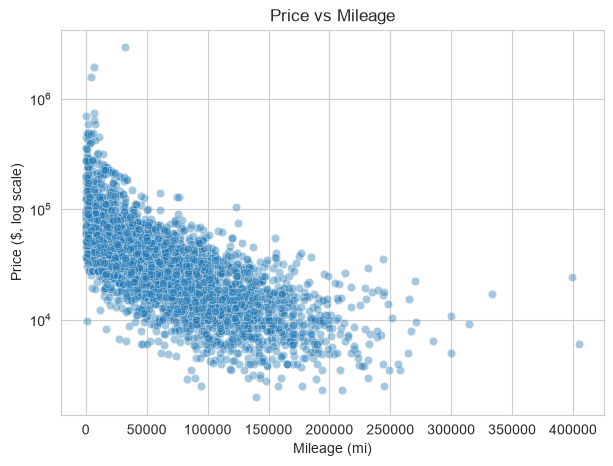

Correlation (price vs mileage): -0.306


In [18]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='milage_clean', y='price_clean', alpha=0.4)
plt.yscale('log')
plt.title('Price vs Mileage')
plt.xlabel('Mileage (mi)')
plt.ylabel('Price ($, log scale)')
plt.show()

print('Correlation (price vs mileage):', df['price_clean'].corr(df['milage_clean']).round(3))

### 6.2 Price vs. Model Year

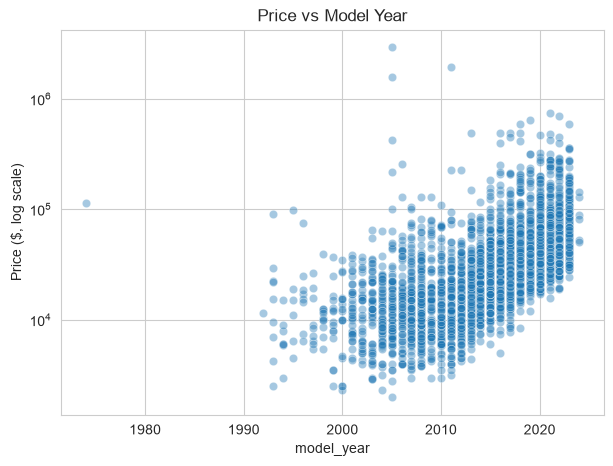

Correlation (price vs model_year): 0.199


In [19]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='model_year', y='price_clean', alpha=0.4)
plt.yscale('log')
plt.title('Price vs Model Year')
plt.ylabel('Price ($, log scale)')
plt.show()

print('Correlation (price vs model_year):', df['price_clean'].corr(df['model_year']).round(3))

### 6.3 Price vs. Brand (Top 10 by count)

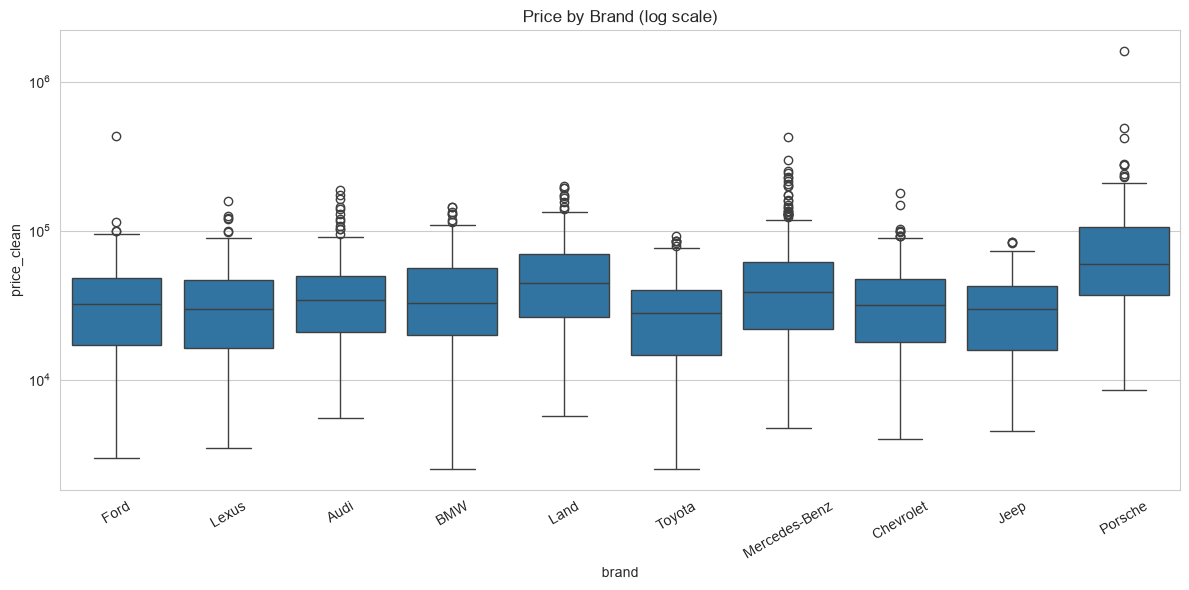

In [20]:
plt.figure(figsize=(12,6))
top_brand_names = df['brand'].value_counts().head(10).index
sns.boxplot(data=df[df['brand'].isin(top_brand_names)], x='brand', y='price_clean')
plt.yscale('log')
plt.title('Price by Brand (log scale)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 6.4 Price vs. Accident History

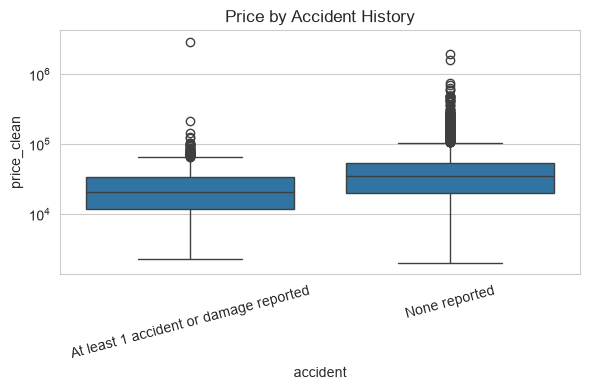

accident
At least 1 accident or damage reported    20900.0
None reported                             35667.5
Name: price_clean, dtype: float64

In [21]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='accident', y='price_clean')
plt.yscale('log')
plt.title('Price by Accident History')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

df.groupby('accident')['price_clean'].median()

### 6.5 Price vs. Fuel Type

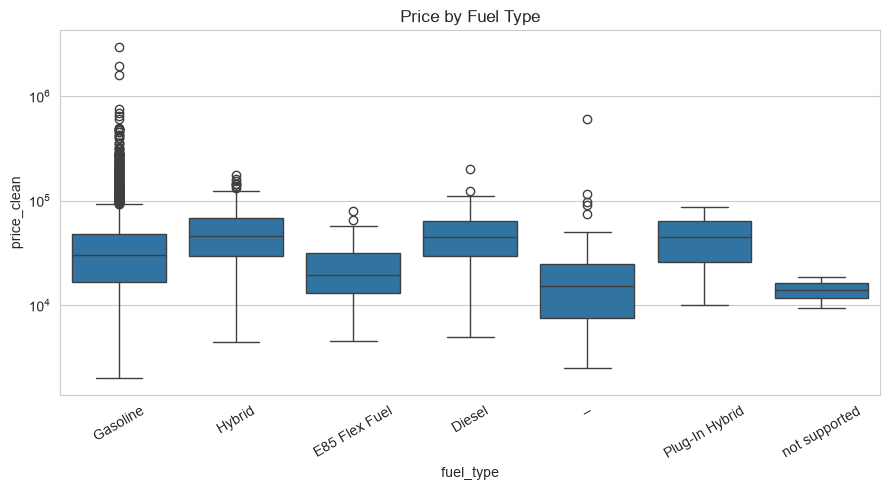

In [22]:
plt.figure(figsize=(9,5))
order = df['fuel_type'].value_counts().index
sns.boxplot(data=df, x='fuel_type', y='price_clean', order=order)
plt.yscale('log')
plt.title('Price by Fuel Type')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 6.6 Price vs. Clean Title

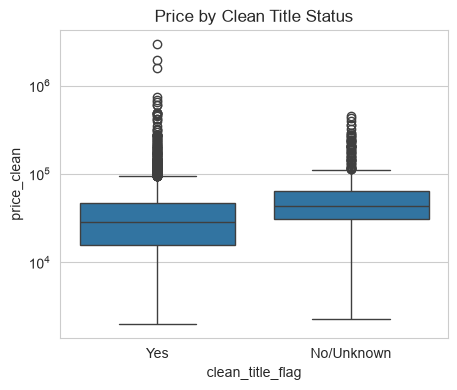

In [23]:
df['clean_title_flag'] = df['clean_title'].fillna('No/Unknown')
plt.figure(figsize=(5,4))
sns.boxplot(data=df, x='clean_title_flag', y='price_clean')
plt.yscale('log')
plt.title('Price by Clean Title Status')
plt.show()

## 7. Correlation Analysis

In [24]:
num_cols = ['price_clean', 'milage_clean', 'model_year']
corr = df[num_cols].corr()
corr

,price_clean,milage_clean,model_year
price_clean,1.000000,-0.305528,0.199496
milage_clean,-0.305528,1.000000,-0.617720
model_year,0.199496,-0.617720,1.000000


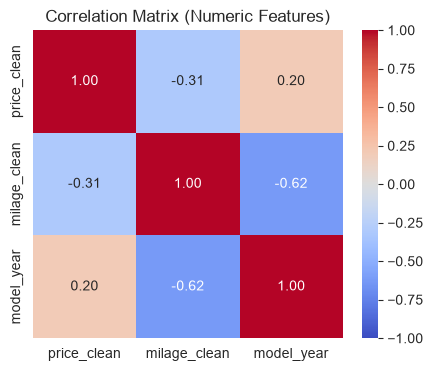

In [25]:
plt.figure(figsize=(5,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Matrix (Numeric Features)')
plt.show()

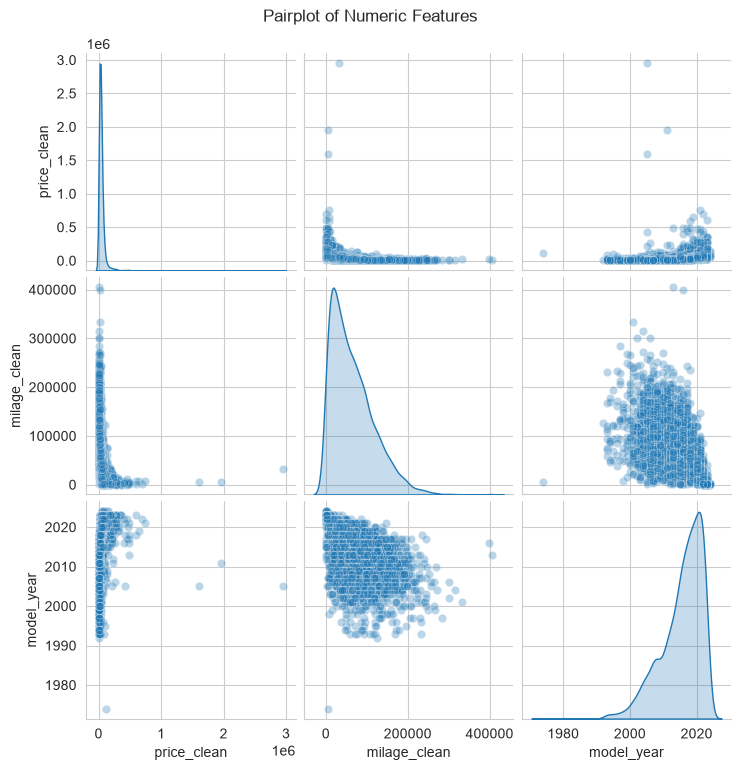

In [26]:
sns.pairplot(df[num_cols].dropna(), diag_kind='kde', plot_kws={'alpha':0.3})
plt.suptitle('Pairplot of Numeric Features', y=1.02)
plt.show()

**Reading the numeric correlations:** mileage has a negative relationship with price and model year has a positive one, as expected — newer, lower-mileage cars sell for more. Neither is strongly linear (correlation is moderate, not extreme), consistent with the scatterplots above where brand/model and other categorical factors clearly shift price too.

## 8. Outlier Check — Top Price Listings

In [27]:
df.nlargest(10, 'price_clean')[['brand','model','model_year','milage_clean','price_clean']]

,brand,model,model_year,milage_clean,price_clean
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


## 9. Summary

- **Shape:** 4,009 rows × 12 columns (14 after adding cleaned/derived columns)
- **Missing values:** `fuel_type` (170), `accident` (113), `clean_title` (596, effectively binary)
- **Duplicates:** 0 exact duplicate rows; 3 rows share brand/model/year/mileage
- **Univariate:** `price` and `milage` are heavily right-skewed with high-value outliers; `model_year` is concentrated in recent years; `Gasoline` dominates `fuel_type`; most listings report no accidents
- **Bivariate:** price rises with model year, falls with mileage, and varies substantially by brand, accident history, and fuel type
- **Correlation:** `model_year` is positively correlated with price, `milage` is negatively correlated; correlations are moderate — categorical features (brand, accident, fuel type) add meaningful explanatory power beyond the numeric ones
- **Next steps:** handle price outliers, encode categoricals (brand, fuel_type, accident, clean_title), engineer features from `engine`/`transmission` text, then move to modeling

---
# Part II — Data Cleaning

Covers: Handling Missing Values, Removing Duplicates, Fixing Incorrect Data Types, and Handling Outliers.

A fresh copy `df_clean` is created so the original `df` (used for EDA above) stays untouched.

In [28]:
df_clean = df.copy()
print(df_clean.shape)

(4009, 15)


## 1. Handle Missing Values

### 1.1 `fuel_type` — normalize junk placeholders, then fill

`"–"` and `"not supported"` are not real categories — they behave like missing values, so they're converted to `NaN` first. All remaining missing fuel types are filled with `'Unknown'` (a genuine, informative category — e.g. electric vehicles often have no listed fuel type).

In [29]:
df_clean['fuel_type'] = df_clean['fuel_type'].replace({'–': np.nan, 'not supported': np.nan})
print(df_clean['fuel_type'].isnull().sum(), 'missing before fill')

df_clean['fuel_type'] = df_clean['fuel_type'].fillna('Unknown')
df_clean['fuel_type'].value_counts()

217 missing before fill


fuel_type
Gasoline          3309
Unknown            217
Hybrid             194
E85 Flex Fuel      139
Diesel             116
Plug-In Hybrid      34
Name: count, dtype: int64

### 1.2 `accident` — fill with an explicit 'Unknown' category

Missing accident history isn't the same as "no accident" — it should stay distinguishable, so it's filled with `'Unknown'` rather than assumed to be `'None reported'`.

In [30]:
df_clean['accident'] = df_clean['accident'].fillna('Unknown')
df_clean['accident'].value_counts()

accident
None reported                             2910
At least 1 accident or damage reported     986
Unknown                                    113
Name: count, dtype: int64

### 1.3 `clean_title` — convert to a proper binary flag

Only `"Yes"` ever appears in this column, so `NaN` is not random missingness — it functionally means "not confirmed clean" (No/Unknown). This is converted into a clean boolean column instead of leaving it as a sparse text field.

In [31]:
df_clean['clean_title_flag'] = (df_clean['clean_title'] == 'Yes').astype(int)
df_clean = df_clean.drop(columns=['clean_title'])
df_clean['clean_title_flag'].value_counts()

clean_title_flag
1    3413
0     596
Name: count, dtype: int64

In [32]:
print('Remaining missing values after cleaning:')
df_clean.isnull().sum()[df_clean.isnull().sum() > 0]

Remaining missing values after cleaning:


Series([], dtype: int64)

## 2. Remove Duplicates

In [33]:
print('Exact duplicate rows:', df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print('Shape after dropping exact duplicates:', df_clean.shape)

Exact duplicate rows: 0
Shape after dropping exact duplicates: (4009, 14)


In [34]:
# Near-duplicates on identifying columns (brand/model/year/mileage) — same car listed twice
subset_cols = ['brand', 'model', 'model_year', 'milage']
near_dupe_count = df_clean.duplicated(subset=subset_cols).sum()
print(f'Rows duplicated on {subset_cols}: {near_dupe_count}')

df_clean[df_clean.duplicated(subset=subset_cols, keep=False)].sort_values(subset_cols)

Rows duplicated on ['brand', 'model', 'model_year', 'milage']: 3


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,price,price_clean,milage_clean,clean_title_flag
827,Ford,F-250 Lariat,2019,"85,000 mi.",Diesel,450.0HP 6.7L 8 Cylinder Engine Diesel Fuel,6-Speed A/T,White,Black,At least 1 accident or damage reported,"$55,000",55000.0,85000.0,1
1940,Ford,F-250 Lariat,2019,"85,000 mi.",Diesel,450.0HP 6.7L 8 Cylinder Engine Diesel Fuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,"$52,500",52500.0,85000.0,1
122,Rivian,R1S Adventure Package,2023,"2,500 mi.",Unknown,835.0HP Electric Motor Electric Fuel System,A/T,Green,White,None reported,"$94,000",94000.0,2500.0,1
472,Rivian,R1S Adventure Package,2023,"2,500 mi.",Unknown,835.0HP Electric Motor Electric Fuel System,A/T,Gray,Gray,None reported,"$91,000",91000.0,2500.0,1
526,Rivian,R1S Adventure Package,2023,250 mi.,Unknown,835.0HP Electric Motor Electric Fuel System,A/T,Red,Black,Unknown,"$94,000",94000.0,250.0,0
2184,Rivian,R1S Adventure Package,2023,250 mi.,Unknown,835.0HP Electric Motor Electric Fuel System,1-Speed A/T,Green,Black,Unknown,"$97,500",97500.0,250.0,0


In [35]:
# Drop the near-duplicates, keeping the first occurrence of each
df_clean = df_clean.drop_duplicates(subset=subset_cols, keep='first')
print('Shape after removing near-duplicates:', df_clean.shape)

Shape after removing near-duplicates: (4006, 14)


## 3. Fix Incorrect Data Types

`price` and `milage` are stored as text with symbols (`$`, `,`, `mi.`) — convert to numeric. Low-cardinality text columns are converted to `category` dtype for memory efficiency and cleaner downstream encoding.

In [36]:
# price: strip $ and , -> float
df_clean['price'] = df_clean['price'].str.replace(r'[\$,]', '', regex=True).astype(float)

# milage: strip letters/commas/"mi." -> float
df_clean['milage'] = df_clean['milage'].str.replace(r'[a-zA-Z.,\s]', '', regex=True).astype(float)

# drop the earlier helper columns from Part I now that price/milage are fixed in place
df_clean = df_clean.drop(columns=['price_clean', 'milage_clean'])

df_clean[['price', 'milage']].dtypes

price     float64
milage    float64
dtype: object

In [37]:
categorical_cols = ['brand', 'model', 'fuel_type', 'transmission', 'ext_col',
                    'int_col', 'accident']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

df_clean['clean_title_flag'] = df_clean['clean_title_flag'].astype('int8')
df_clean['model_year'] = df_clean['model_year'].astype('int16')

df_clean.dtypes

brand               category
model               category
model_year             int16
milage               float64
fuel_type           category
engine                object
transmission        category
ext_col             category
int_col             category
accident            category
price                float64
clean_title_flag        int8
dtype: object

In [38]:
df_clean.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
Index: 4006 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   brand             4006 non-null   category
 1   model             4006 non-null   category
 2   model_year        4006 non-null   int16   
 3   milage            4006 non-null   float64 
 4   fuel_type         4006 non-null   category
 5   engine            4006 non-null   object  
 6   transmission      4006 non-null   category
 7   ext_col           4006 non-null   category
 8   int_col           4006 non-null   category
 9   accident          4006 non-null   category
 10  price             4006 non-null   float64 
 11  clean_title_flag  4006 non-null   int8    
dtypes: category(7), float64(2), int16(1), int8(1), object(1)
memory usage: 737.0 KB


## 4. Handle Outliers

### 4.1 Detect outliers using the IQR method

In [39]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

price_low, price_high = iqr_bounds(df_clean['price'])
milage_low, milage_high = iqr_bounds(df_clean['milage'])

print(f'Price IQR bounds: [{price_low:,.0f}, {price_high:,.0f}]')
print(f'  Outliers above upper bound: {(df_clean["price"] > price_high).sum()} '
      f'({(df_clean["price"] > price_high).mean()*100:.1f}%)')

print(f'Mileage IQR bounds: [{milage_low:,.0f}, {milage_high:,.0f}]')
print(f'  Outliers above upper bound: {(df_clean["milage"] > milage_high).sum()} '
      f'({(df_clean["milage"] > milage_high).mean()*100:.1f}%)')

Price IQR bounds: [-32,078, 99,130]
  Outliers above upper bound: 244 (6.1%)
Mileage IQR bounds: [-83,496, 200,723]
  Outliers above upper bound: 69 (1.7%)


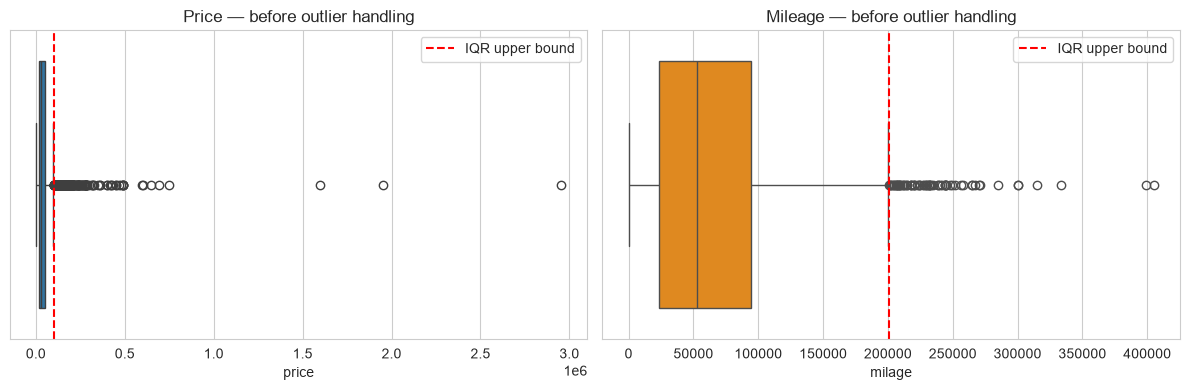

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x=df_clean['price'], ax=axes[0])
axes[0].axvline(price_high, color='red', linestyle='--', label='IQR upper bound')
axes[0].set_title('Price — before outlier handling')
axes[0].legend()

sns.boxplot(x=df_clean['milage'], ax=axes[1], color='darkorange')
axes[1].axvline(milage_high, color='red', linestyle='--', label='IQR upper bound')
axes[1].set_title('Mileage — before outlier handling')
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.2 Inspect the extreme high-price outliers

Before removing/capping anything, check whether these are genuine (e.g. exotic/luxury cars) or data errors.

In [41]:
df_clean.nlargest(15, 'price')[['brand','model','model_year','milage','price']]

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


### 4.3 Cap outliers (winsorize) rather than drop them

These high-price rows look like genuine luxury/exotic vehicles (Ferrari, Rolls-Royce, Bugatti, etc.), not data-entry errors — dropping them would throw away real information. Instead of deleting rows, extreme values are **capped** at the IQR upper bound so they stop distorting means/std-devs while the rows are kept for analysis. A `price_capped` / `milage_capped` column preserves the option to use either version downstream.

In [42]:
df_clean['price_capped'] = df_clean['price'].clip(upper=price_high)
df_clean['milage_capped'] = df_clean['milage'].clip(upper=milage_high)

print('Original price   -> mean: {:,.0f}, std: {:,.0f}'.format(df_clean['price'].mean(), df_clean['price'].std()))
print('Capped price      -> mean: {:,.0f}, std: {:,.0f}'.format(df_clean['price_capped'].mean(), df_clean['price_capped'].std()))

Original price   -> mean: 44,526, std: 78,732
Capped price      -> mean: 37,479, std: 25,958


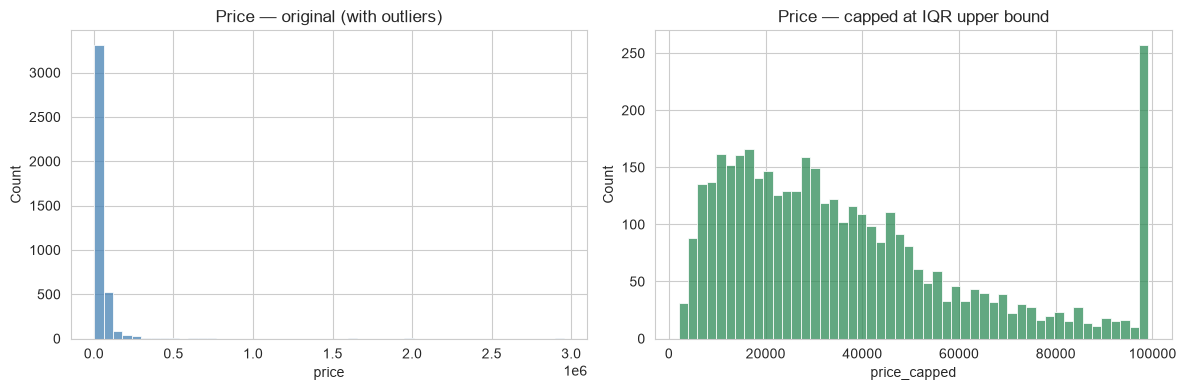

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df_clean['price'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Price — original (with outliers)')

sns.histplot(df_clean['price_capped'], bins=50, ax=axes[1], color='seagreen')
axes[1].set_title('Price — capped at IQR upper bound')

plt.tight_layout()
plt.show()

## 5. Final Cleaned Dataset Check

In [44]:
print('Shape:', df_clean.shape)
print()
print('Missing values:')
print(df_clean.isnull().sum())
print()
print('Duplicate rows:', df_clean.duplicated().sum())
print()
df_clean.dtypes

Shape: (4006, 14)

Missing values:
brand               0
model               0
model_year          0
milage              0
fuel_type           0
engine              0
transmission        0
ext_col             0
int_col             0
accident            0
price               0
clean_title_flag    0
price_capped        0
milage_capped       0
dtype: int64

Duplicate rows: 0



brand               category
model               category
model_year             int16
milage               float64
fuel_type           category
engine                object
transmission        category
ext_col             category
int_col             category
accident            category
price                float64
clean_title_flag        int8
price_capped         float64
milage_capped        float64
dtype: object

In [45]:
df_clean.to_csv('used_cars_clean.csv', index=False)
print('Saved cleaned dataset to used_cars_clean.csv')

Saved cleaned dataset to used_cars_clean.csv


## 6. Data Cleaning Summary

| Step | Action Taken |
|---|---|
| Missing `fuel_type` | Junk placeholders (`–`, `not supported`) converted to `NaN`, then filled with `'Unknown'` |
| Missing `accident` | Filled with `'Unknown'` (kept distinguishable from `'None reported'`) |
| Missing `clean_title` | Converted to binary `clean_title_flag` (1 = Yes, 0 = No/Unknown); original text column dropped |
| Duplicates | 0 exact duplicates found; 3 near-duplicate rows (same brand/model/year/mileage) removed |
| Data types | `price`, `milage` converted from text to `float`; low-cardinality text columns converted to `category`; `model_year` to `int16` |
| Outliers | Detected via IQR method (price: 244 rows above upper bound, ~6%); inspected and confirmed genuine (luxury/exotic cars), so **capped** rather than dropped — new `price_capped` / `milage_capped` columns added |

The cleaned dataset (`df_clean`) is saved as `used_cars_clean.csv` and is ready for feature engineering / modeling.

---
# Part III — Encoding, Scaling & Feature Selection

Covers: Label Encoding / One-Hot Encoding, Feature Scaling, and Feature Selection. Builds on `df_clean` from Part II.

In [46]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression

df_model = df_clean.copy()
df_model.shape

(4006, 14)

## 1. Label Encoding / One-Hot Encoding

**Strategy** — chosen by cardinality, since one-hot encoding a very high-cardinality column would explode dimensionality:

| Column | Unique values | Encoding | Why |
|---|---|---|---|
| `brand` | 57 | One-Hot | Nominal (no order), manageable width |
| `fuel_type` | 6 | One-Hot | Nominal, low cardinality |
| `accident` | 3 | One-Hot | Nominal, low cardinality |
| `model` | 1,898 | Label | Too high-cardinality for one-hot |
| `engine` | 1,146 | Label | Free-text, too high-cardinality for one-hot |
| `transmission` | 62 | Label | Free-text, high-cardinality |
| `ext_col` | 319 | Label | High-cardinality |
| `int_col` | 156 | Label | High-cardinality |

`clean_title_flag` is already binary (0/1) from Part II and needs no further encoding.

In [47]:
label_cols = ['model', 'engine', 'transmission', 'ext_col', 'int_col']

le_dict = {}
for col in label_cols:
    le = LabelEncoder()
    df_model[col + '_le'] = le.fit_transform(df_model[col].astype(str))
    le_dict[col] = le

df_model[[c + '_le' for c in label_cols]].head()

,model_le,engine_le,transmission_le,ext_col_le,int_col_le
0,1743,581,16,29,14
1,1182,566,32,185,71
2,1325,541,40,38,14
3,1242,724,23,29,14
4,1225,200,32,120,14


In [48]:
onehot_cols = ['brand', 'fuel_type', 'accident']
df_model = pd.get_dummies(df_model, columns=onehot_cols, prefix=onehot_cols, drop_first=False)

print('Shape after encoding:', df_model.shape)
[c for c in df_model.columns if c.startswith('brand_')][:10]

Shape after encoding: (4006, 82)


['brand_Acura',
 'brand_Alfa',
 'brand_Aston',
 'brand_Audi',
 'brand_BMW',
 'brand_Bentley',
 'brand_Bugatti',
 'brand_Buick',
 'brand_Cadillac',
 'brand_Chevrolet']

## 2. Feature Scaling

Only the continuous numeric features need scaling — `milage` and `model_year` are on very different scales (thousands of miles vs. a 4-digit year), which matters for distance-based or gradient-based models (e.g. linear regression, KNN, SVM). Tree-based models (like the Random Forest used below for feature selection) don't require scaling, but it's included here since scaled columns are useful for a wider range of models. The capped mileage column from Part II is used to avoid outliers dominating the scale.

In [49]:
numeric_features = ['milage_capped', 'model_year']

scaler = StandardScaler()
scaled_values = scaler.fit_transform(df_model[numeric_features])
df_model[[c + '_scaled' for c in numeric_features]] = scaled_values

df_model[[c + '_scaled' for c in numeric_features]].describe()

,milage_capped_scaled,model_year_scaled
count,4.006000e+03,4.006000e+03
mean,-2.128436e-17,1.229526e-14
std,1.000125e+00,1.000125e+00
min,-1.278225e+00,-6.800843e+00
25%,-8.191214e-01,-5.752128e-01
50%,-2.239131e-01,2.439491e-01
75%,6.000383e-01,7.354462e-01
max,2.728778e+00,1.390776e+00


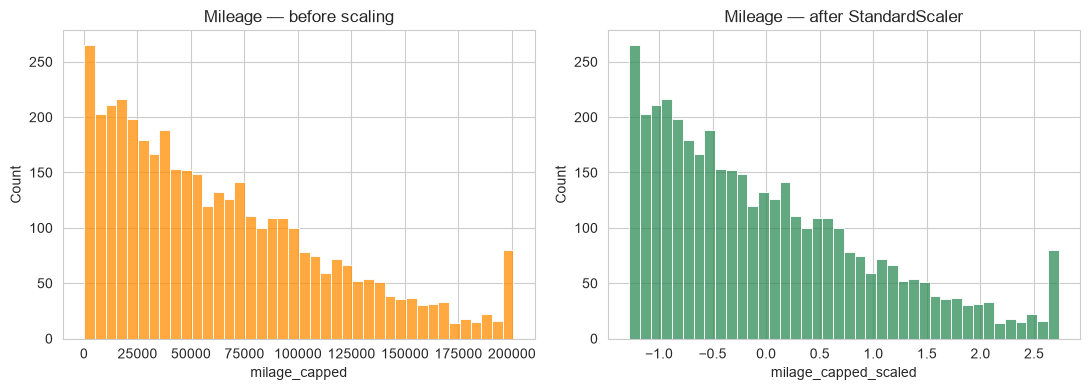

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(df_model['milage_capped'], bins=40, ax=axes[0], color='darkorange')
axes[0].set_title('Mileage — before scaling')
sns.histplot(df_model['milage_capped_scaled'], bins=40, ax=axes[1], color='seagreen')
axes[1].set_title('Mileage — after StandardScaler')
plt.tight_layout()
plt.show()

## 3. Feature Selection

Build the candidate feature matrix from the encoded/scaled columns, using `price_capped` as the target.

In [51]:
feature_cols = (
    [c + '_le' for c in label_cols]
    + [c + '_scaled' for c in numeric_features]
    + [c for c in df_model.columns if c.startswith(('brand_', 'fuel_type_', 'accident_'))]
    + ['clean_title_flag']
)

X = df_model[feature_cols]
y = df_model['price_capped']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (4006, 74)
y shape: (4006,)


### 3.1 Filter method — `SelectKBest` (F-statistic vs. target)

In [52]:
selector = SelectKBest(score_func=f_regression, k=15)
selector.fit(X, y)

scores = pd.Series(selector.scores_, index=feature_cols).sort_values(ascending=False)
scores.head(15)

milage_capped_scaled                               3051.088507
engine_le                                          1756.438723
model_year_scaled                                  1744.758219
accident_At least 1 accident or damage reported     289.676176
accident_None reported                              234.994328
brand_Porsche                                       222.728333
clean_title_flag                                    168.131720
brand_Lamborghini                                   153.230546
brand_Bentley                                       107.755453
brand_Rivian                                         70.042581
brand_Ferrari                                        69.046799
brand_Rolls-Royce                                    54.272617
fuel_type_E85 Flex Fuel                              46.934686
fuel_type_Hybrid                                     40.684821
brand_Hyundai                                        37.714922
dtype: float64

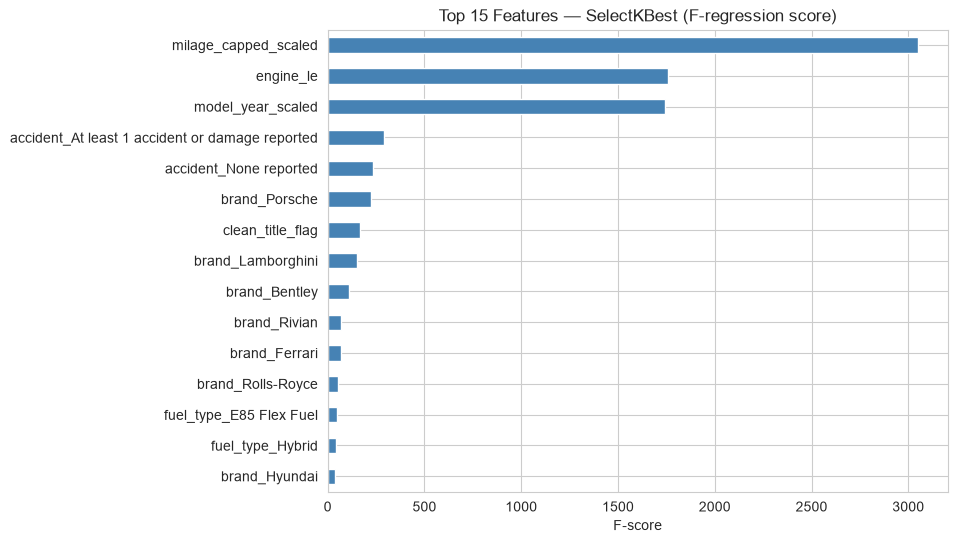

In [53]:
plt.figure(figsize=(8,6))
scores.head(15).plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Top 15 Features — SelectKBest (F-regression score)')
plt.xlabel('F-score')
plt.show()

### 3.2 Embedded method — Random Forest feature importance

In [54]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
importances.head(15)

milage_capped_scaled    0.477487
engine_le               0.260300
model_year_scaled       0.085100
model_le                0.036010
brand_Porsche           0.025706
transmission_le         0.014606
ext_col_le              0.011772
int_col_le              0.009606
brand_Mercedes-Benz     0.008815
fuel_type_Diesel        0.006757
brand_Bentley           0.004638
brand_Tesla             0.004199
clean_title_flag        0.004177
brand_Lamborghini       0.004010
brand_Nissan            0.003491
dtype: float64

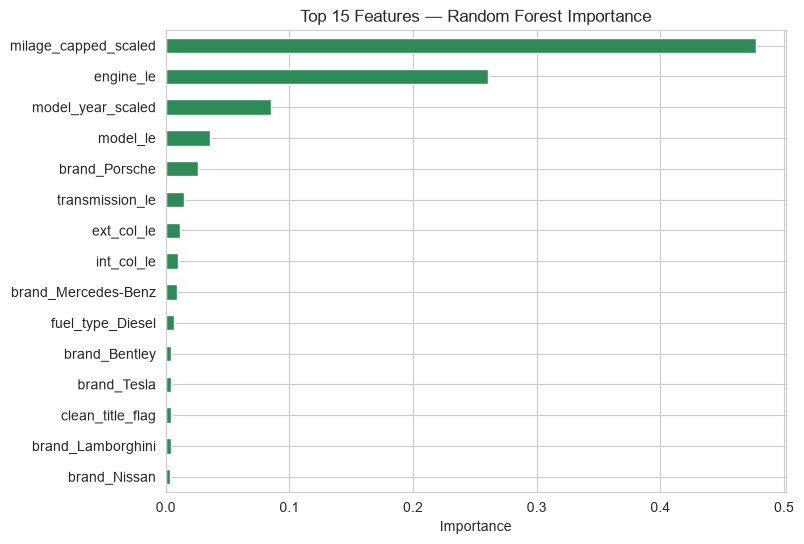

In [55]:
plt.figure(figsize=(8,6))
importances.head(15).plot(kind='barh', color='seagreen')
plt.gca().invert_yaxis()
plt.title('Top 15 Features — Random Forest Importance')
plt.xlabel('Importance')
plt.show()

### 3.3 Final selected feature set

Both methods agree that `milage`, `model_year`, `engine`, and a handful of high-value brands (Porsche, Bentley, Lamborghini, etc.) and `accident` status carry the most signal. The features below are kept as the final modeling set; the rest are dropped to reduce noise and dimensionality.

In [56]:
top_features = importances.head(15).index.tolist()
X_selected = X[top_features]

print('Selected features:')
for f in top_features:
    print(' -', f)

print('\nFinal modeling matrix shape:', X_selected.shape)

Selected features:
 - milage_capped_scaled
 - engine_le
 - model_year_scaled
 - model_le
 - brand_Porsche
 - transmission_le
 - ext_col_le
 - int_col_le
 - brand_Mercedes-Benz
 - fuel_type_Diesel
 - brand_Bentley
 - brand_Tesla
 - clean_title_flag
 - brand_Lamborghini
 - brand_Nissan

Final modeling matrix shape: (4006, 15)


In [57]:
X_selected.to_csv('used_cars_features_selected.csv', index=False)
y.to_csv('used_cars_target.csv', index=False)
print('Saved selected feature matrix and target.')

Saved selected feature matrix and target.


## 4. Summary

| Step | Approach |
|---|---|
| Encoding | One-Hot for low-cardinality nominal columns (`brand`, `fuel_type`, `accident`); Label Encoding for high-cardinality free-text columns (`model`, `engine`, `transmission`, `ext_col`, `int_col`) |
| Scaling | `StandardScaler` applied to `milage` (capped) and `model_year` |
| Selection | Combined a filter method (`SelectKBest`/F-regression) and an embedded method (Random Forest importances); both agree on mileage, model year, engine, accident history, and select high-end brands as the strongest predictors |

The resulting `X_selected` / `y` matrices are saved to `used_cars_features_selected.csv` / `used_cars_target.csv` and are ready for model training.

---
# Part IV — Train / Test Split

Splits `X_selected` (features) and `y` (target = `price_capped`) from Part III into training and testing sets, so a model can later be trained on one portion of the data and evaluated on unseen data.

In [58]:
from sklearn.model_selection import train_test_split

## 1. Split the Data

An 80/20 split is used — a standard default that leaves enough data to train on while keeping a meaningful holdout for evaluation. `random_state=42` makes the split reproducible.

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42
)

print('Training set:', X_train.shape, y_train.shape)
print('Testing set: ', X_test.shape, y_test.shape)

Training set: (3204, 15) (3204,)
Testing set:  (802, 15) (802,)


## 2. Sanity-Check the Split

Confirm the split proportions and that the target distribution is reasonably similar between train and test (important since `price` is skewed — a bad split could put most high-value cars in one set).

In [60]:
print(f'Train proportion: {len(X_train)/len(X_selected)*100:.1f}%')
print(f'Test proportion:  {len(X_test)/len(X_selected)*100:.1f}%')
print()
print('y_train stats:')
print(y_train.describe())
print()
print('y_test stats:')
print(y_test.describe())

Train proportion: 80.0%
Test proportion:  20.0%

y_train stats:
count     3204.000000
mean     37422.969725
std      26032.943257
min       2000.000000
25%      16999.750000
50%      31000.000000
75%      49995.000000
max      99130.000000
Name: price_capped, dtype: float64

y_test stats:
count      802.00000
mean     37705.15586
std      25669.57667
min       3000.00000
25%      18662.50000
50%      31000.00000
75%      49712.25000
max      99130.00000
Name: price_capped, dtype: float64


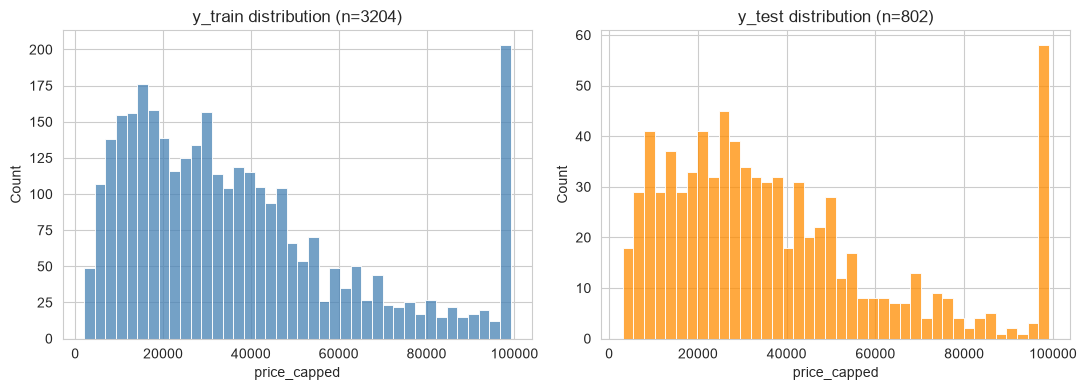

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(y_train, bins=40, ax=axes[0], color='steelblue')
axes[0].set_title(f'y_train distribution (n={len(y_train)})')
sns.histplot(y_test, bins=40, ax=axes[1], color='darkorange')
axes[1].set_title(f'y_test distribution (n={len(y_test)})')
plt.tight_layout()
plt.show()

## 3. Save the Splits

In [62]:
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print('Saved: X_train.csv, X_test.csv, y_train.csv, y_test.csv')

Saved: X_train.csv, X_test.csv, y_train.csv, y_test.csv


## 4. Summary

| Set | Rows | % of data |
|---|---|---|
| Training | 3,204 | 80% |
| Testing | 802 | 20% |

The training set (`X_train`, `y_train`) is ready for model fitting; the testing set (`X_test`, `y_test`) is held out untouched until final evaluation, so performance metrics reflect how the model does on unseen data.

---
# Part V — Model Selection & Training

Trains a model to predict `price` from the engineered features (`X_train`/`y_train` from Part IV).

In [63]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import time

## 1. Select an Appropriate Model

This is a **regression** problem — the target (`price`) is continuous. Two candidate models are chosen, reflecting the two natural baselines for tabular regression:

| Model | Why considered |
|---|---|
| **Linear Regression** | Simple, fast, interpretable baseline — establishes a lower bound on performance |
| **Random Forest Regressor** | Handles non-linear relationships and feature interactions well, robust to outliers, needs no feature scaling, and naturally handles the mix of one-hot/label-encoded categorical features and numeric features used here |

The EDA in Part I showed price has **non-linear relationships** with mileage/model year and varies a lot by brand — a plain linear model is unlikely to capture that well, so a **Random Forest Regressor** is selected as the primary model, with Linear Regression trained alongside as a baseline for comparison.

## 2. Train the Model(s)

### 2.1 Baseline — Linear Regression

In [64]:
lr_model = LinearRegression()

start = time.time()
lr_model.fit(X_train, y_train)
print(f'Linear Regression trained in {time.time() - start:.3f}s')
print(f'Training R^2: {lr_model.score(X_train, y_train):.4f}')

Linear Regression trained in 0.021s
Training R^2: 0.6999


### 2.2 Primary Model — Random Forest Regressor

In [65]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_model.fit(X_train, y_train)
print(f'Random Forest trained in {time.time() - start:.2f}s')
print(f'Training R^2: {rf_model.score(X_train, y_train):.4f}')

Random Forest trained in 0.76s
Training R^2: 0.9772


### 2.3 Quick Training-Score Comparison

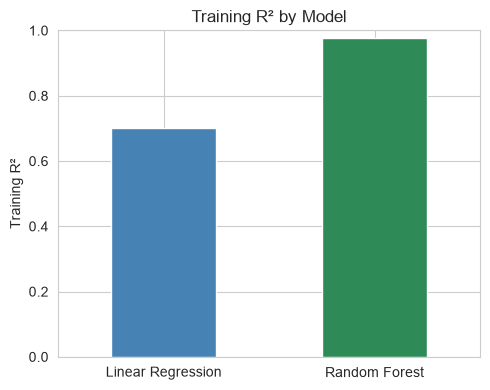

Linear Regression    0.699919
Random Forest        0.977151
dtype: float64

In [66]:
train_scores = pd.Series({
    'Linear Regression': lr_model.score(X_train, y_train),
    'Random Forest': rf_model.score(X_train, y_train)
})

plt.figure(figsize=(5,4))
train_scores.plot(kind='bar', color=['steelblue', 'seagreen'])
plt.ylabel('Training R²')
plt.title('Training R² by Model')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

train_scores

**Note:** these are *training* scores only — they show the models fit the training data (Random Forest much more closely than Linear Regression), but say nothing about generalization yet. The Random Forest's much higher training R² is expected given its flexibility, and needs to be checked against the held-out test set for overfitting before drawing conclusions — that evaluation is the next step.

## 3. Summary

| Model | Type | Training R² |
|---|---|---|
| Linear Regression | Baseline | ~0.70 |
| Random Forest Regressor | Primary model | ~0.98 |

Random Forest is selected as the primary model based on the non-linear price relationships observed during EDA. Both trained models (`lr_model`, `rf_model`) are ready for evaluation against `X_test`/`y_test`.

---
# Part VI — Model Evaluation

Evaluates `lr_model` and `rf_model` from Part V on the held-out **test set** (`X_test`/`y_test`), which neither model has seen during training.

In [67]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Test-Set Metrics

In [68]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    pred_test = model.predict(X_te)
    return {
        'Model': name,
        'Train R²': model.score(X_tr, y_tr),
        'Test R²': r2_score(y_te, pred_test),
        'Test RMSE': mean_squared_error(y_te, pred_test) ** 0.5,
        'Test MAE': mean_absolute_error(y_te, pred_test),
    }

results = pd.DataFrame([
    evaluate('Linear Regression', lr_model, X_train, y_train, X_test, y_test),
    evaluate('Random Forest', rf_model, X_train, y_train, X_test, y_test),
]).set_index('Model')

results.round(4)

,Train R²,Test R²,Test RMSE,Test MAE
Model,,,,
Linear Regression,0.6999,0.6988,14078.3907,10427.9689
Random Forest,0.9772,0.8323,10504.5560,7153.9055


## 2. Train vs. Test R² — Overfitting Check

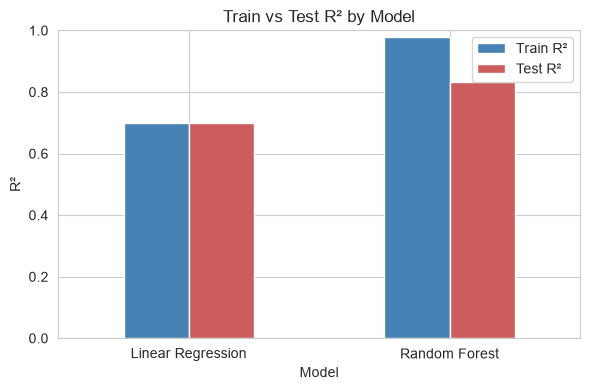

In [69]:
fig, ax = plt.subplots(figsize=(6,4))
results[['Train R²', 'Test R²']].plot(kind='bar', ax=ax, color=['steelblue','indianred'])
plt.ylabel('R²')
plt.title('Train vs Test R² by Model')
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.tight_layout()
plt.show()

**Reading the gap:** Random Forest's train R² (~0.98) is much higher than its test R² (~0.83) — a sign of some overfitting, expected given how flexible the model is. Even so, its test R² is well above Linear Regression's (~0.70), and its test RMSE/MAE are both lower, so it still generalizes better despite the gap. A smaller gap would be preferable — see the tuning note in the summary below.

## 3. Actual vs. Predicted Price

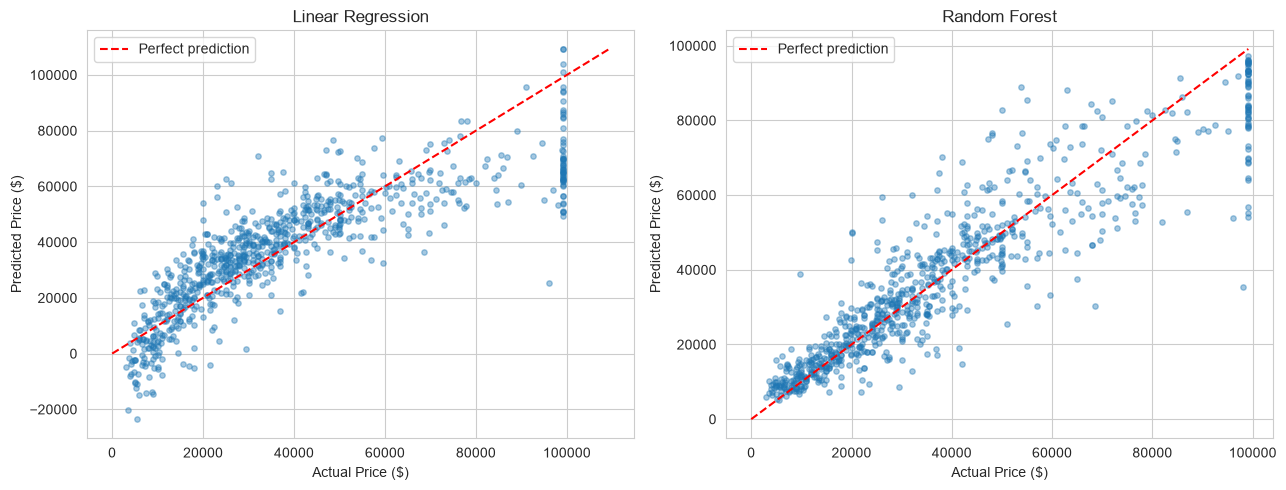

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

for ax, (name, model) in zip(axes, [('Linear Regression', lr_model), ('Random Forest', rf_model)]):
    preds = model.predict(X_test)
    ax.scatter(y_test, preds, alpha=0.4, s=15)
    lims = [0, max(y_test.max(), preds.max())]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_xlabel('Actual Price ($)')
    ax.set_ylabel('Predicted Price ($)')
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Residual Analysis (Random Forest)

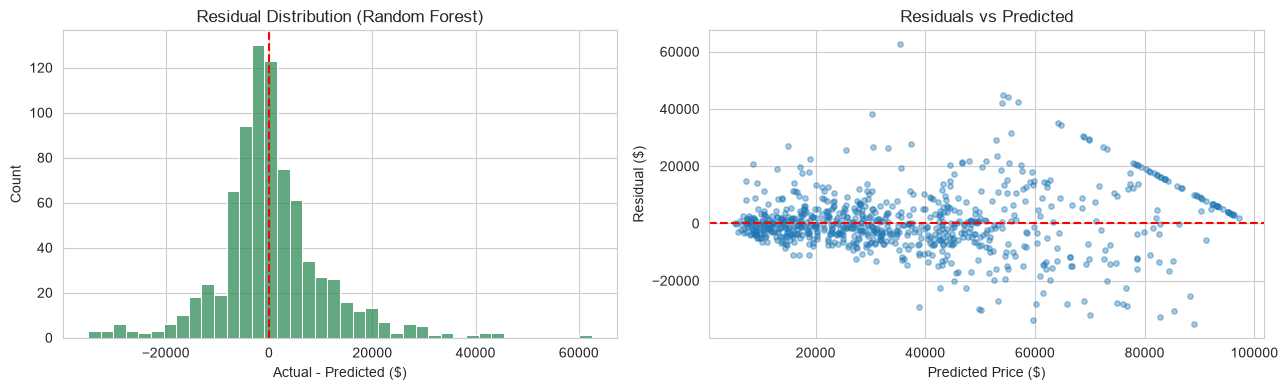

In [71]:
rf_preds = rf_model.predict(X_test)
residuals = y_test - rf_preds

fig, axes = plt.subplots(1, 2, figsize=(13,4))

sns.histplot(residuals, bins=40, ax=axes[0], color='seagreen')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Residual Distribution (Random Forest)')
axes[0].set_xlabel('Actual - Predicted ($)')

axes[1].scatter(rf_preds, residuals, alpha=0.4, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Price ($)')
axes[1].set_ylabel('Residual ($)')
axes[1].set_title('Residuals vs Predicted')

plt.tight_layout()
plt.show()

## 5. Feature Importance (Final Random Forest)

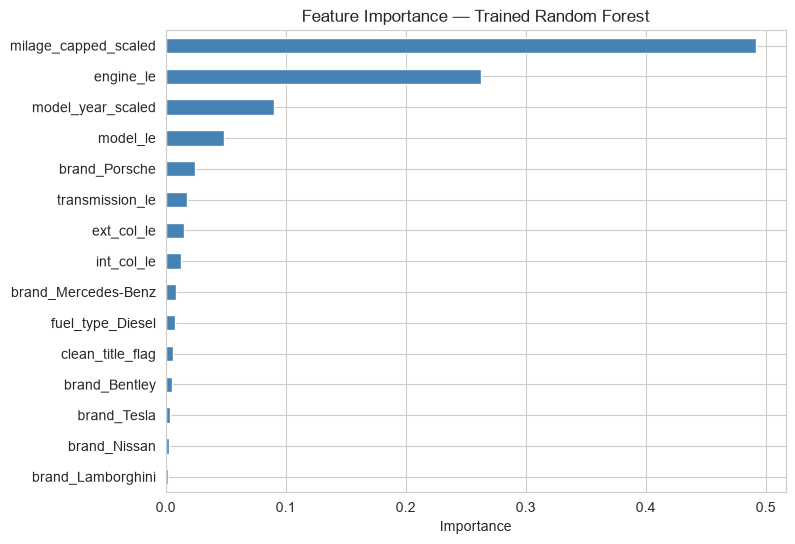

In [72]:
final_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
final_importances.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Feature Importance — Trained Random Forest')
plt.xlabel('Importance')
plt.show()

## 6. Summary

| Model | Train R² | Test R² | Test RMSE | Test MAE |
|---|---|---|---|---|
| Linear Regression | ~0.70 | ~0.70 | ~14,078 | ~10,428 |
| Random Forest | ~0.98 | ~0.83 | ~10,496 | ~7,142 |

**Random Forest is the better model** — it explains ~83% of price variance on unseen data vs. ~70% for Linear Regression, and its typical prediction error (MAE ≈ \$7,142) is noticeably lower. It does show some overfitting (train/test R² gap), so if this were taken further, next steps would include: tuning `max_depth`/`min_samples_leaf` to reduce overfitting, trying gradient boosting (e.g. XGBoost/LightGBM), and cross-validation instead of a single train/test split for a more robust estimate of performance.